In [9]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients

dti_week = 0

# normalize DTI metrics
dti.loc[dti.side == 'ipsilesional', 'ratio' ] = dti.loc[dti.side == 'ipsilesional', 'mean'].values /  dti.loc[dti.side == 'contralesional', 'mean'].values
dti['log_ratio'] = np.log(dti['ratio'])
dti = dti[(dti.regionname == 'CST_R') & (dti.Week == dti_week) & (dti.metric == 'FaMap')] # W0 FA as measure of integrity of affected CST


# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[2]
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]
left_cerebel = cerebel[cerebel.hemisphere == 'L'][['subj_id', 'Week', 'region', 'regionname', 'regionname_bilat', 'mean']].rename(columns = {'mean': 'left_mean'})
right_cerebel = cerebel[cerebel.hemisphere == 'R'][['subj_id', 'Week', 'region', 'regionname', 'regionname_bilat', 'mean']].rename(columns = {'mean': 'right_mean'})

#normalize cerebellar volume
norm_cerebel = left_cerebel.merge(right_cerebel, on = ['subj_id', 'Week', 'regionname_bilat'], suffixes = ('_left', '_right'))
norm_cerebel['left_norm'] = norm_cerebel['left_mean']/norm_cerebel['right_mean']
cerebel = norm_cerebel

dti_cerebel = pd.merge(dti, cerebel, on = 'subj_id', suffixes = ('_dti', '_cerebel'))

/localscratch/tmp/ipykernel_28888/625840781.py:10: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


### pearson r for correlation between: rFA in affected CST at W0; normalized GMV in affected cerebellar ROI

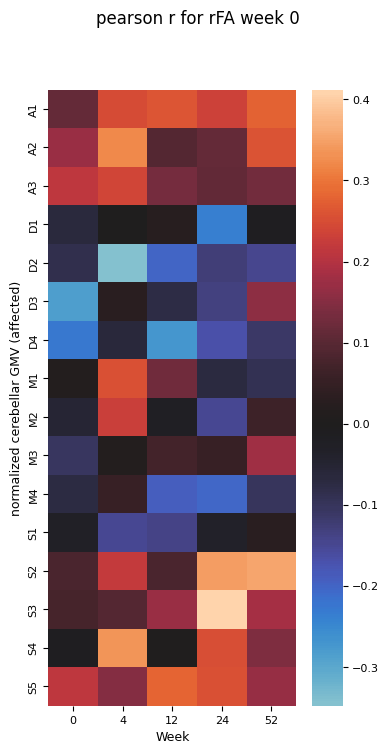

In [10]:
rows = []
# this is using NORMALIZED CEREBELLAR VOLUME ONLY IN LEFT ROIs
for week in gl.weeks:
    for roi in dti_cerebel.regionname_bilat.unique():
        corr_df = dti_cerebel[(dti_cerebel.Week_cerebel == week) & (dti_cerebel.regionname_bilat == roi)]
        r_stat, p_val = stats.pearsonr(corr_df['log_ratio'],corr_df['left_norm'])
        rows.append({'Week': week, 'roi': roi, 'r_stat': r_stat, 'p_val': p_val})
r_df = pd.DataFrame(rows)


# heatmap
heat = r_df.pivot(index = 'roi', columns = 'Week', values = 'r_stat')
fig, ax = plt.subplots(figsize = (4,8))
sns.heatmap(heat, center = 0, ax = ax)
fig.suptitle(f"pearson r for rFA week {dti_week}")
plt.ylabel("normalized cerebellar GMV (affected)")
plt.show()

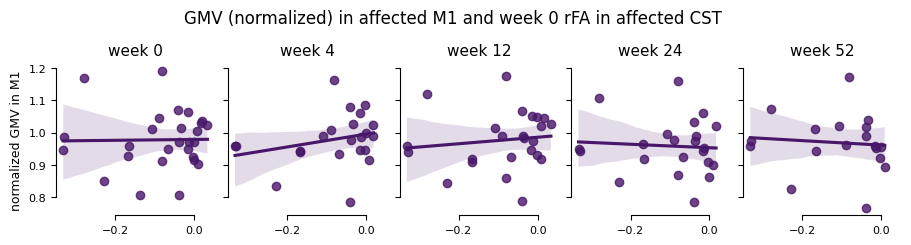

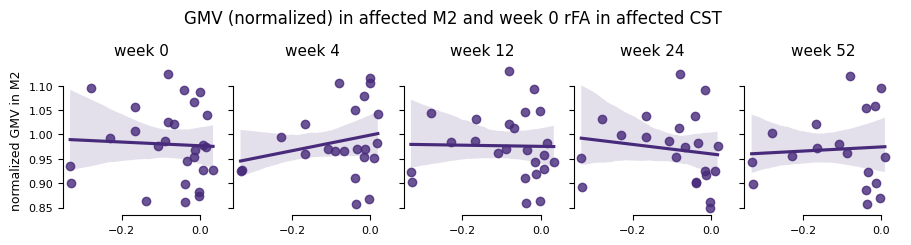

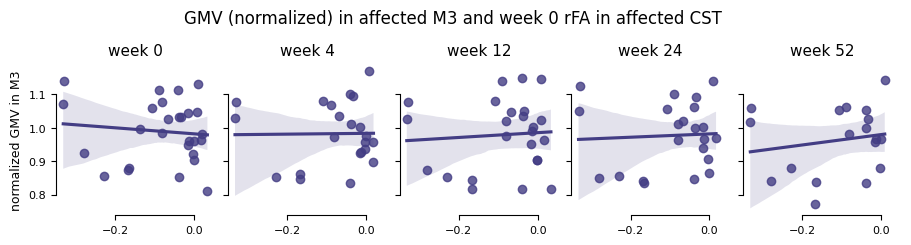

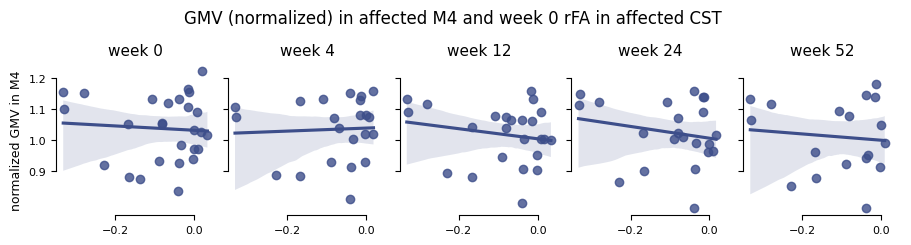

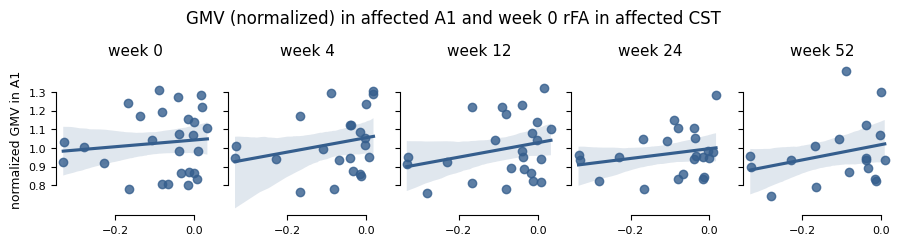

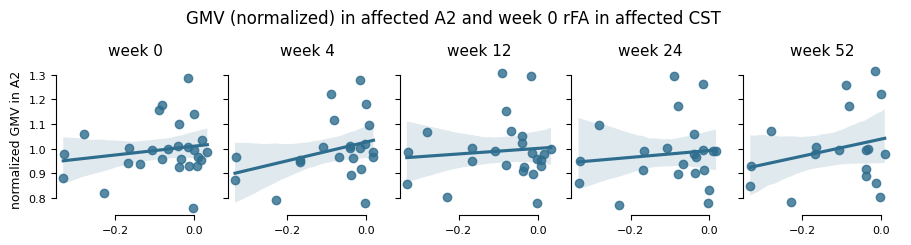

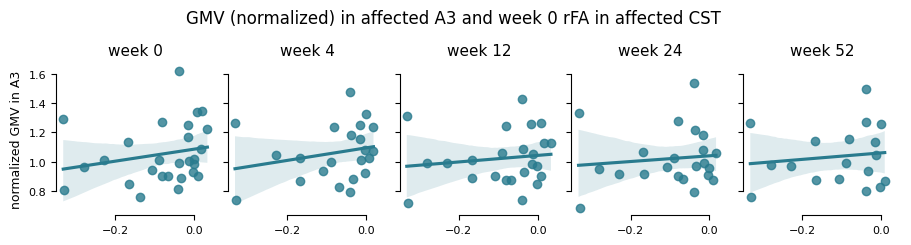

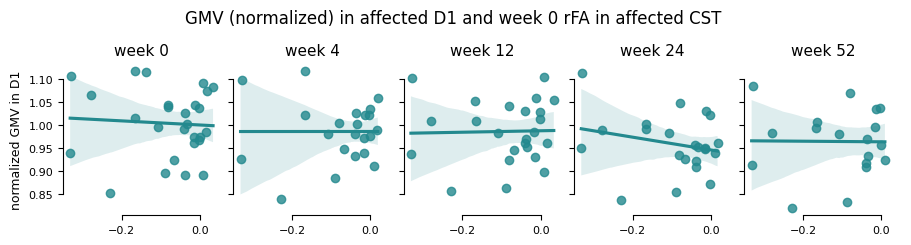

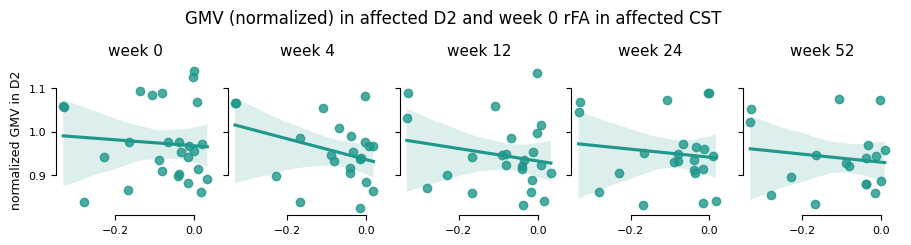

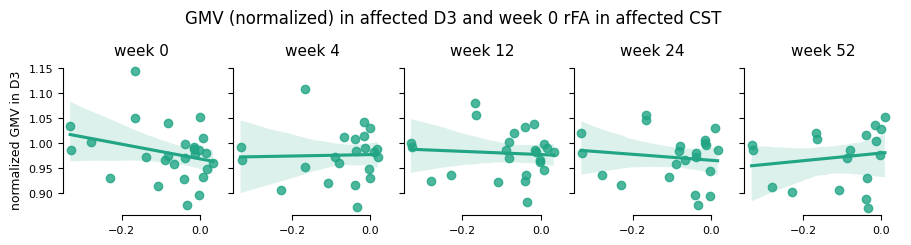

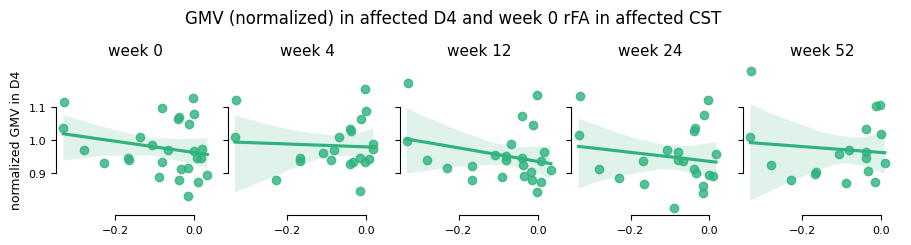

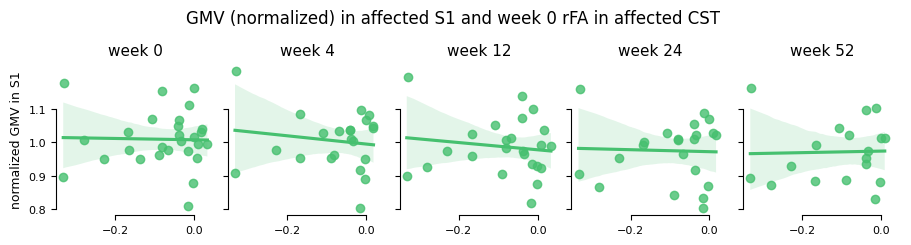

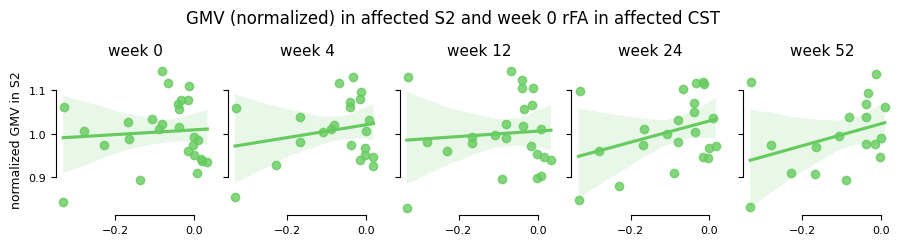

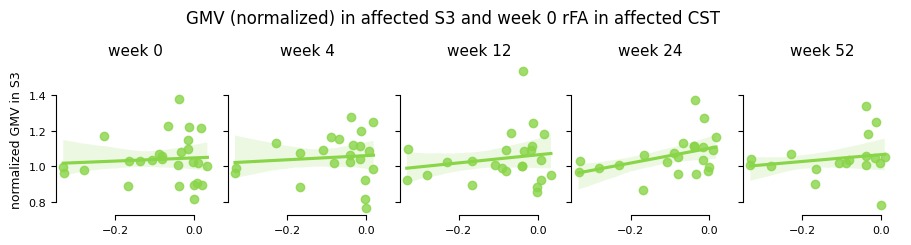

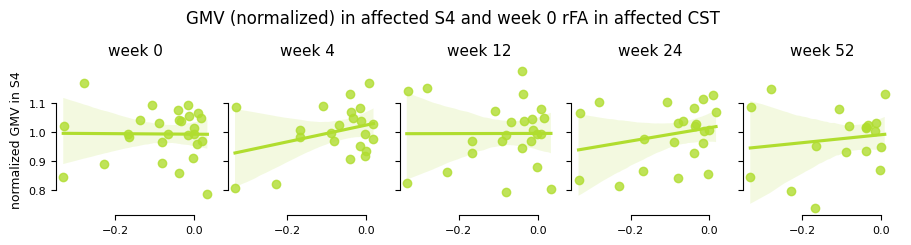

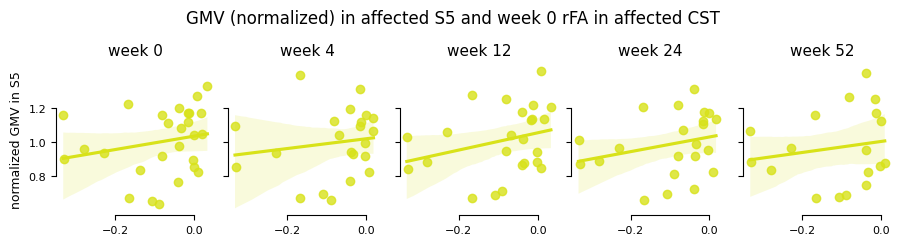

In [11]:
colors = sns.color_palette('viridis', n_colors = len(dti_cerebel.regionname_bilat.unique()))

for r, roi in enumerate(dti_cerebel.regionname_bilat.unique()):

    fig, axs = plt.subplots(1, 5, figsize = (9,2), sharex = True, sharey = True, constrained_layout = True)
    for i, week in enumerate(gl.weeks):
        ax = axs[i]
        sns.regplot(x = 'log_ratio', y = 'left_norm', data = dti_cerebel[(dti_cerebel.regionname_bilat == roi) & (dti_cerebel.Week_cerebel == week)], ax = ax, color = colors[r])
        sns.despine(trim = True)

        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.set_title(f'week {week}')
        
    axs[0].set_ylabel(f"normalized GMV in {roi}")
    fig.suptitle(f'GMV (normalized) in affected {roi} and week {dti_week} rFA in affected CST ', y = 1.15)
    plt.show()
